# 03. Give every plant a place to go

Connect tabs and detail screens while preserving the identity of each individual specimen.

**45 minutes including practice · Seedling**

This is a **Python 3 notebook**. It contains the complete lesson, embedded vector illustrations, React Native examples for reading, and executable Python models. Python does not run React Native. Run the `.tsx` exercise in Expo using the workbook instructions. No cloud credentials or live services are needed for the notebook.

Run the cells from top to bottom. Change a control, make a prediction, then explain the result. If widgets are unavailable, edit a model's default arguments and rerun its cell.

If you have the complete course folder, [open the interactive guide](../index.html#lesson-03) or [read the exercise instructions](../exercises/README.md). These companion links are absent in a notebooks-only or single-lesson download; the notebook itself still runs independently.


## What you will be able to do

- You can translate an Expo Router filename into a route.
- You can pass a specimen ID into a dynamic detail screen.
- You can explain why route parameters do not authorize access to a record.

## Before you begin

You can pass a plant summary and a callback into a card.

You can distinguish an ID from a visible name.


In [1]:
from IPython.display import display, HTML, SVG
import json
import os
import inspect

# Widgets are optional. Without them, edit parameters and rerun the model cell.
try:
    if os.environ.get('PLANTOPEDIA_NO_WIDGETS') == '1':
        raise ImportError('Widget-free verification mode')
    import ipywidgets as widgets
except ImportError:
    widgets = None

def explore(function, **controls):
    if widgets is not None:
        display(widgets.interactive(function, **controls))
    else:
        print('Optional controls are unavailable. Edit the explorer function defaults and rerun this model cell.')
        defaults = {name: parameter.default for name, parameter in inspect.signature(function).parameters.items()}
        print('Using function defaults:', defaults)
        function()

print('Python teaching model ready. React Native TSX runs separately in Expo.')


Python teaching model ready. React Native TSX runs separately in Expo.


The east balcony lemon and the west window lemon look similar in a list. Selecting either should open that particular tree’s history. Navigation needs an identity that survives renaming, reordering, and a later identification correction. The label a reader sees is useful context, but the stable specimen ID determines which record the app opens.

Plantopedia uses Expo Router to connect file structure with screen structure. This lesson adds navigation to the card from lesson 02. You will separate tab destinations from detail screens, inspect a route parameter, and consider a reader who opens a detail link directly without first visiting the list.


## Read the file tree as a map

Inside src/app, a regular filename becomes a route segment. The file search.tsx corresponds to /search. An index.tsx file is the default screen for its containing route. The parentheses in (tabs) create a route group: they organize screens and layouts without adding “(tabs)” to the public URL.

The file plants/[plantId].tsx contains square brackets because plantId is a value supplied by the destination. For example, /plants/lemon_east and /plants/lemon_west use the same screen component with different IDs. A layout file named _layout.tsx describes how its child screens relate through a stack, tabs, or shared providers.

In this app, src/app/_layout.tsx establishes the outer stack and shared providers, while src/app/(tabs)/_layout.tsx configures the tab area. You do not need to add a different component file for every saved tree. One detail route plus a parameter can display many individual histories. Keep non-route helpers in src/components, src/services, or a feature directory so the app directory remains a readable screen map.


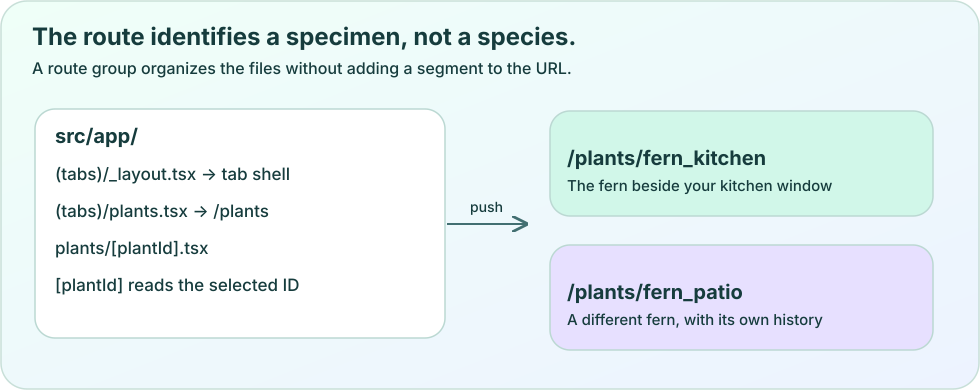

In [2]:
# Embedded original vector illustration; no external image files are required.
display(SVG(data='<svg xmlns="http://www.w3.org/2000/svg" width="980" height="390" viewBox="0 0 980 390" role="img" aria-labelledby="title desc"><title id="title">Files, URLs, and specimen identity</title><desc id="desc">The tabs route group is omitted from URLs. plants/[plantId].tsx receives a stable specimen ID. Two ferns have different paths and histories even if they share a scientific name.</desc><defs>\n<linearGradient id="bg" x2="1" y2="1"><stop stop-color="#effff8"/><stop offset="1" stop-color="#edf3ff"/></linearGradient>\n<linearGradient id="leaf" x2="1" y2="1"><stop stop-color="#37e6b0"/><stop offset="1" stop-color="#07886c"/></linearGradient>\n<linearGradient id="glass" x2="1" y2="1"><stop stop-color="#fff" stop-opacity=".94"/><stop offset="1" stop-color="#e2efff" stop-opacity=".72"/></linearGradient>\n<linearGradient id="violet" x2="1" y2="1"><stop stop-color="#a58cff"/><stop offset="1" stop-color="#6550d9"/></linearGradient>\n<marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0 0L8 4L0 8" fill="none" stroke="#426f71" stroke-width="1.4"/></marker>\n</defs><g font-family="system-ui,-apple-system,Segoe UI,sans-serif"><rect x="1" y="1" width="978" height="388" rx="26" fill="url(#bg)" stroke="#c8dfd8" stroke-width="1.5"/><text x="32" y="45" font-size="24" fill="#163c3d" font-weight="750" text-anchor="start">The route identifies a specimen, not a species.</text><text x="32" y="74" font-size="16" fill="#163c3d" font-weight="500" text-anchor="start">A route group organizes the files without adding a segment to the URL.</text><rect x="35" y="109" width="410" height="229" rx="20" fill="#fff" stroke="#bbd8d2" stroke-width="1.5"/><text x="55" y="143" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">src/app/</text><text x="55" y="180" font-size="17" fill="#163c3d" font-weight="500" text-anchor="start">(tabs)/_layout.tsx  →  tab shell</text><text x="55" y="217" font-size="17" fill="#163c3d" font-weight="500" text-anchor="start">(tabs)/plants.tsx  →  /plants</text><text x="55" y="254" font-size="17" fill="#163c3d" font-weight="500" text-anchor="start">plants/[plantId].tsx</text><text x="55" y="291" font-size="17" fill="#163c3d" font-weight="500" text-anchor="start">[plantId] reads the selected ID</text><path d="M447 224L526 224" stroke="#426f71" stroke-width="2" fill="none" marker-end="url(#arrow)"/><text x="486.5" y="212.0" font-size="14" fill="#163c3d" font-weight="500" text-anchor="middle">push</text><rect x="550" y="111" width="383" height="105" rx="20" fill="#d1f7e9" stroke="#bbd8d2" stroke-width="1.5"/><text x="567" y="165" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">/plants/fern_kitchen</text><text x="567" y="191" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">The fern beside your kitchen window</text><rect x="550" y="245" width="383" height="105" rx="20" fill="#e7e0ff" stroke="#bbd8d2" stroke-width="1.5"/><text x="567" y="299" font-size="20" fill="#163c3d" font-weight="700" text-anchor="start">/plants/fern_patio</text><text x="567" y="325" font-size="15" fill="#163c3d" font-weight="500" text-anchor="start">A different fern, with its own history</text></g></svg>'))


**Selected routes in this checkout**

Read this example here; TSX runs in Expo, while shell commands run in a terminal. This notebook uses a Python kernel.

```text
src/app/
  _layout.tsx                 → shared providers and outer stack
  (tabs)/
    _layout.tsx               → tab navigation
    index.tsx                 → /
    plants.tsx                → /plants
    scan.tsx                  → /scan
  search.tsx                  → /search
  plants/[plantId].tsx        → /plants/<one specimen ID>
  species/[speciesId].tsx     → /species/<one catalog species ID>
```


## Turn a press into a specific destination

The router exposes navigation functions that an event handler can call. push adds a destination to the navigation history. back returns through available history, while replace changes the current entry. Use the choice that matches the journey you want the reader to experience; the fact that all three can change the visible screen does not make their back behavior identical.

The teaching button below receives a specimen ID and sends it as the dynamic plantId parameter. Using the named pathname makes the connection between the file’s bracket name and the supplied parameter visible. The destination contains only the record identity. It does not contain a photograph, a whole mutable plant object, or a session token.

Passing an entire plant through a link would create a second copy of information that can become stale. Suppose the nickname changes on another device. A detail screen should load the current record for its ID, rather than trust the old nickname embedded in navigation. The next API lesson adds that loading step. For now, trace how the same button opens two different IDs.


**Teaching component: OpenPlantButton.tsx**

Read this example here; TSX runs in Expo, while shell commands run in a terminal. This notebook uses a Python kernel.

```tsx
import { useRouter } from "expo-router";
import { Button } from "react-native";

type Props = { plantId: string; nickname: string };
export function OpenPlantButton({ plantId, nickname }: Props) {
  const router = useRouter();
  return (
    <Button title={`Open ${nickname}`} onPress={() => {
      router.push({
        pathname: "/plants/[plantId]",
        params: { plantId },
      });
    }} />
  );
}
```


## Read the parameter before using it

A route parameter is external input. A reader can type or change a URL; a link might also be old or malformed. The TypeScript type you supply to a hook helps you write code, but it does not prove that an incoming value obeys the application’s rules. Runtime validation performs that separate check.

The teaching detail route below uses the existing shared Id schema. It accepts one string and rejects an absent, repeated, or malformed value. The component deliberately displays the validated ID rather than pretending it has already loaded a plant. In lesson 05, that ID becomes part of the query key and API call.

The example includes a back action with a fallback. A detail screen opened from a list usually has a previous entry. A fresh deep link may not. Asking whether the router can go back prevents the screen from relying on a visit that never happened. The fallback replaces the current destination with /plants so the reader still has a clear way into the collection.


**Teaching route: src/app/plants/[plantId].tsx in a learning copy**

Read this example here; TSX runs in Expo, while shell commands run in a terminal. This notebook uses a Python kernel.

```tsx
import { Id } from "@plantopedia/contracts";
import { useLocalSearchParams, useRouter } from "expo-router";
import { Button, Text, View } from "react-native";

export default function PlantIdentityScreen() {
  const { plantId } = useLocalSearchParams<{
    plantId?: string | string[];
  }>();
  const router = useRouter();
  const parsed = Id.safeParse(plantId);
  function leave() {
    if (router.canGoBack()) router.back();
    else router.replace("/plants");
  }
  return (
    <View style={{ padding: 24, gap: 16 }}>
      <Text>{parsed.success
        ? `Specimen ID: ${parsed.data}`
        : "This plant link is not valid."}</Text>
      <Button title="Back to your garden" onPress={leave} />
    </View>
  );
}
```


## Keep a species page separate from a specimen page

A species describes a kind of plant. A specimen describes one particular plant someone photographed or saved. Both lemon trees may link to the same species catalog entry, while keeping different specimen IDs, photographs, observations, ownership, and places.

This distinction appears in the route tree. A species catalog page lives at species/[speciesId].tsx, while a saved individual lives at plants/[plantId].tsx. A care description for the species can help both trees. A note saying “I moved this tree into the shade today” belongs to one specimen. Routing by scientific name would collapse these different purposes.

Try renaming “East balcony lemon” to “Kitchen lemon.” Its specimen ID should stay the same, and a saved detail link should continue to identify that tree. Also consider an identification correction: a previously uncertain tree may later have a different scientific name. The specimen’s history should not disappear because its label became more accurate.


> **A route names a request; the server checks permission**
>
> A valid-looking specimen ID does not prove that the current account owns it. The API must authorize the request. Hiding a tab or validating the route string cannot replace that server check.


## Make each destination explain its current state

The current tab layout includes Explore, My Garden, Scan, and Ask. Settings remains routable but is hidden from the main tab bar through its options. This shows that “not visible as a tab” is a presentation choice, not the removal of the route or a permission rule.

A complete detail screen needs to explain loading, missing records, failed requests, and available records. These are different outcomes. A deleted specimen should not be shown as an empty editable record, and a slow connection should not be described as “no plants.” As you add data in later lessons, preserve this distinction between a destination existing and a requested record being available.

For a cross-platform check, open the same specimen from its card on a phone and from its URL on the web. Confirm that both resolve to the same identity. Then open the URL in a fresh browser tab. The second check is valuable because it removes assumptions about previous navigation and in-memory screen data.


## Experiment: predict, change, explain

Choose each fixture specimen ID and compare the printed route with the common species ID in the data. The default is fern_kitchen. Read the rename assertions and explain why the route stays the same after a nickname changes. This dropdown has no navigation history or Back button; the browser lab and Expo Router exercise add those behaviors.

The cell below is a bounded Python analogy of the lesson. Its fixtures do not call the app API, request permission, or certify device behavior. Its assertions check the stated model only.


In [3]:
from urllib.parse import quote

specimens = [
    {'id': 'fern_kitchen', 'nickname': 'Kitchen fern', 'speciesId': 'same_fern_species'},
    {'id': 'fern_patio', 'nickname': 'Patio fern', 'speciesId': 'same_fern_species'},
]

def specimen_route(identifier):
    if not isinstance(identifier, str) or not identifier.strip():
        raise ValueError('A specimen ID is required')
    return '/plants/' + quote(identifier, safe='')

def explore_route(identifier='fern_kitchen'):
    print('Route file: src/app/plants/[plantId].tsx')
    print('URL:', specimen_route(identifier))
    print('The (tabs) group is not a URL segment.')

explore(explore_route, identifier=[p['id'] for p in specimens])
assert specimens[0]['speciesId'] == specimens[1]['speciesId']
assert specimen_route(specimens[0]['id']) != specimen_route(specimens[1]['id'])
renamed = {**specimens[0], 'nickname': 'The window fern'}
assert specimen_route(renamed['id']) == specimen_route(specimens[0]['id'])
print('Renaming preserves the route. Sharing a species does not merge specimens.')


interactive(children=(Dropdown(description='identifier', options=('fern_kitchen', 'fern_patio'), value='fern_k…

Renaming preserves the route. Sharing a species does not merge specimens.


## Make a prediction of your own

Create routes for the two fixtures without using their common species ID.

Replace `None` below. A blank answer reports **not attempted**; it is never counted as passing. The check gives feedback without interrupting “Run All.”


In [4]:
your_answer = None  # Replace with [specimen_route(p['id']) for p in specimens].
if your_answer is None:
    print('Not attempted. Replace None, then rerun this cell.')
elif your_answer == ['/plants/fern_kitchen', '/plants/fern_patio']:
    print('Correct. '+'Each specimen keeps its own route even when both specimens share a species.')
else:
    print('Revisit your prediction. '+'Each specimen keeps its own route even when both specimens share a species.')


Not attempted. Replace None, then rerun this cell.


## Retrieve the ideas

**1. What URL does src/app/(tabs)/plants.tsx represent?**

1. /(tabs)/plants
2. /plants
3. /tabs/plants.tsx

**2. Two saved trees have the same scientific name. What should identify their detail routes?**

1. Two distinct specimen IDs.
2. The scientific name alone.
3. Their current array positions.

**3. A route parameter passes the Id schema. What has this proved?**

1. The current account owns the plant.
2. The plant definitely exists on the server.
3. The value has the expected identifier shape.

Set each value in the next cell to your selected option number, starting at 1. You can change it and rerun for more feedback.


In [5]:
quiz = [{'question': 'What URL does src/app/(tabs)/plants.tsx represent?', 'options': ['/(tabs)/plants', '/plants', '/tabs/plants.tsx'], 'answer': 1, 'explanation': 'The parentheses mark a route group and do not add a URL segment. The group can still provide a shared layout, so leaving it out of the URL does not make it meaningless.'}, {'question': 'Two saved trees have the same scientific name. What should identify their detail routes?', 'options': ['Two distinct specimen IDs.', 'The scientific name alone.', 'Their current array positions.'], 'answer': 0, 'explanation': 'Each specimen needs a persistent identity for its own history. A shared species label cannot distinguish the trees, and an array position changes when the collection is reordered.'}, {'question': 'A route parameter passes the Id schema. What has this proved?', 'options': ['The current account owns the plant.', 'The plant definitely exists on the server.', 'The value has the expected identifier shape.'], 'answer': 2, 'explanation': 'Shape validation rejects malformed input. Existence and authorization require separate server checks. A syntactically valid ID can still refer to a missing or inaccessible record.'}]
answers = [None, None, None]  # Replace None with 1, 2, or 3.
correct = 0
for number, (question, answer) in enumerate(zip(quiz, answers), 1):
    if answer is None:
        print(f'{number}. Not attempted.')
    elif type(answer) is not int or answer not in range(1, len(question['options']) + 1):
        print(f'{number}. Choose a valid option number.')
    else:
        right = answer - 1 == question['answer']
        correct += int(right)
        print(f"{number}. {'Correct' if right else 'Revisit this idea'}. {question['explanation']}")
print(f'{correct} of {len(quiz)} correct; unanswered questions do not count as passing.')


1. Not attempted.
2. Not attempted.
3. Not attempted.
0 of 3 correct; unanswered questions do not count as passing.


## Build in Expo: Follow two specimens through one detail route

Connect the teaching cards to a dynamic route in a separate learning copy, then verify normal and direct-link journeys.

1. Create two sample lemon-tree summaries with different IDs and the same species name.
2. Replace the card’s alert callback with router.push using /plants/[plantId] and the selected ID.
3. Display the validated route parameter on the teaching detail screen.
4. Rename one specimen without changing its ID and explain why its saved route still has the same identity.
5. Open a detail URL directly on web and provide a Back fallback when no prior screen exists.
6. Describe, in writing, where a request for another account’s specimen must be rejected.

### Check your result

- [ ] Each card opens the same route component with its own ID.
- [ ] The route group does not appear in the public URL.
- [ ] Malformed input produces an explanatory state.
- [ ] The direct-link journey provides a usable exit even without prior history.

Download the matching exercise bundle from the HTML course, or use the `exercises` folder if you downloaded the complete course. A notebooks-only download does not include that folder. Files under `docs/tutorials` do not become Expo routes until copied as instructed. The numbered workbook supplies a related concrete practice task; the inline exercise can ask you to extend it.


<details><summary>Hint</summary>

The bracket name plantId and the params object key must agree. Keep the hook calls above conditional rendering branches.

</details>

<details><summary>Worked reasoning / solution</summary>

```text
The parent callback calls router.push({ pathname: "/plants/[plantId]", params: { plantId: id } }). The destination reads useLocalSearchParams, validates the value with Id.safeParse, and displays either the validated identity or an invalid-link message. Use router.canGoBack() before router.back(), otherwise replace with /plants. Keep the nickname and species as display data; only the stable specimen ID chooses this history.
```

</details>


## Explain it in your own words

A plant is renamed and later identified as a different species. Explain which routes should stay stable, which catalog link may change, and where the observation history belongs.

*Write your explanation in the Markdown cell below. Save the notebook to keep your work.*


My explanation:

<!-- Replace this comment with a connected explanation and an example. -->


## Find this idea in the app

- [src/app/(tabs)/_layout.tsx](../../../src/app/(tabs)/_layout.tsx) — Declares the main tab destinations and hides Settings from the tab bar.

- [src/app/plants/[plantId].tsx](../../../src/app/plants/[plantId].tsx) — Reads the specimen route parameter and loads its owner-scoped detail query.

- [src/app/species/[speciesId].tsx](../../../src/app/species/[speciesId].tsx) — Provides the distinct destination for shared species catalog information.

- [packages/contracts/src/index.ts](../../../packages/contracts/src/index.ts) — Defines the runtime Id schema and separate record relationships.

Repository links require this notebook to remain in the checkout’s `docs/tutorials/notebooks` folder. Downloaded notebooks still contain every explanation and embedded diagram.

## Primary documentation

- [Expo Router file notation](https://docs.expo.dev/router/basics/notation/)
- [Expo Router navigation](https://docs.expo.dev/router/basics/navigation/)


## Carry these ideas forward

- Route groups organize layouts without changing public URL segments.
- A dynamic route lets one component display many individual records.
- Parameter validation, record existence, and account permission are separate checks.
